# 02 · Baseline: TF-IDF n-grams with classical models

TF-IDF turns a text into a long vector: one number per word pair or character sequence, high when the n-gram is
frequent in this text but rare in the others. Linear models then learn one weight per n-gram and class.
All vectorizers are fitted on training rows only; every score is on the fixed validation fold from notebook 01.

In [1]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-generated-text-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwkit import env
from hwkit.download import ensure_data
from hwkit.tracker import Run
P = env.setup(seed=42)
ensure_data(P)

platform: local
    data: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data
 outputs: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs
   cache: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs/cache
    repo: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection
  device: mps
data ready at /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data


PosixPath('/Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data')

In [2]:
# Imports, config, data with the fixed split from notebook 01 (texts cut to the first max_chars characters)
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.naive_bayes import ComplementNB
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC

from hwkit.config import load_config
from hwkit.split import LABELS, load_split, scores
from hwkit.submission import make_submission

NOTEBOOK_START = time.time()
cfg = load_config("baseline")
FIG = P.outputs / "figures"
FIG.mkdir(parents=True, exist_ok=True)
METRICS = ["macro_f1_testlike", "macro_f1", "accuracy", "f1_human", "f1_fusion", "f1_ai"]

def prepare(df):
    df["domain_lang"] = df["domain"] + " | " + df["lang"]
    df["text_cut"] = df["text"].str[:cfg["data"]["max_chars"]]
    return df.drop(columns="text")

train = prepare(load_split(pd.read_csv(P.data / "train.csv")))
test = prepare(pd.read_csv(P.data / "test.csv"))
val = train[train["fold"] == 0].reset_index(drop=True)
fit_small = train[train["sub40k"]].reset_index(drop=True)
fit_big = train[train["fold"] != 0].sample(n=cfg["data"]["final_train_size"], random_state=42).reset_index(drop=True)
del train
gc.collect()
run = Run("baseline_tfidf", cfg, P)
print(f"search: {len(fit_small)} training texts; final: {len(fit_big)}; validation: {len(val)}; test: {len(test)}")

run 'baseline_tfidf' at /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs/runs/baseline_tfidf  done: nothing yet
search: 40002 training texts; final: 80000; validation: 27236; test: 25000


## Small parameter search on the fixed 40k subsample

Three feature sets (word 1–2-grams, character 3–5-grams, both) × five models: Complement Naive Bayes, a linear SVM
and logistic regression with three regularization strengths C (larger C = weaker regularization, the model follows
the training data more closely). The 40k subsample is the same one the transformer will be trained on.

In [3]:
# TF-IDF vectorizers fitted on the 40k training subsample only, then applied to validation
def make_vectorizers(fc):
    return {kind: TfidfVectorizer(analyzer="word" if kind == "word" else "char_wb",
                                  ngram_range=tuple(fc[kind]["ngram_range"]), min_df=fc[kind]["min_df"],
                                  max_features=fc[kind]["max_features"], lowercase=fc[kind]["lowercase"],
                                  sublinear_tf=True, dtype=np.float32)
            for kind in ("word", "char")}

def features(blocks, kinds):
    """Stack the TF-IDF blocks of a feature set, e.g. 'word+char'."""
    return sp.hstack([blocks[k] for k in kinds.split("+")], format="csr")

t0 = time.time()
vecs = make_vectorizers(cfg["features"])
Xs = {k: v.fit_transform(fit_small["text_cut"]) for k, v in vecs.items()}
Xv = {k: v.transform(val["text_cut"]) for k, v in vecs.items()}
print({k: X.shape for k, X in Xs.items()}, f"{(time.time() - t0) / 60:.1f} min")

{'word': (40002, 200000), 'char': (40002, 200000)} 4.6 min


In [4]:
# Parameter search: every feature set x model, scored on validation (sorted by test-like macro-F1)
def make_models(sc):
    models = {f"ComplementNB alpha={sc['nb_alpha']}": ComplementNB(alpha=sc["nb_alpha"]),
              f"LinearSVC C={sc['svc_C']}": LinearSVC(C=sc["svc_C"], max_iter=5000)}
    models.update({f"LogReg C={c}": LogisticRegression(C=c, max_iter=3000) for c in sc["logreg_C"]})
    return models

y_small = fit_small["label"].to_numpy()
rows = []
for feats in ["word", "char", "word+char"]:
    X_fit, X_val = features(Xs, feats), features(Xv, feats)
    for name, model in make_models(cfg["search"]).items():
        t0 = time.time()
        model.fit(X_fit, y_small)
        rows.append({"features": feats, "model": name, **scores(val["label"], model.predict(X_val), val["weight"]),
                     "minutes": (time.time() - t0) / 60})
    del X_fit, X_val
search = pd.DataFrame(rows).sort_values("macro_f1_testlike", ascending=False).reset_index(drop=True)
search.to_csv(run.dir / "search.csv", index=False)
search.round(4)

,features,model,macro_f1,accuracy,macro_f1_testlike,f1_human,f1_fusion,f1_ai,minutes
0,word+char,LogReg C=32,0.8598,0.8816,0.8538,0.7906,0.8068,0.9819,4.0354
1,word+char,LogReg C=8,0.8583,0.8804,0.8517,0.7894,0.8032,0.9822,4.6966
2,word+char,LogReg C=2,0.8565,0.8789,0.8496,0.7880,0.8001,0.9815,3.0098
3,char,LogReg C=8,0.8489,0.8724,0.8438,0.7737,0.7932,0.9799,3.9323
4,char,LogReg C=32,0.8471,0.8709,0.8425,0.7686,0.7930,0.9795,2.1962
5,char,LogReg C=2,0.8455,0.8693,0.8396,0.7716,0.7868,0.9781,2.5106
6,word+char,LinearSVC C=0.5,0.8455,0.8697,0.8388,0.7744,0.7825,0.9798,1.1111
7,word,LogReg C=32,0.8429,0.8675,0.8335,0.7668,0.7822,0.9798,0.4564
8,char,LinearSVC C=0.5,0.8371,0.8622,0.8316,0.7623,0.7728,0.9761,0.8614
9,word,LogReg C=8,0.8407,0.8656,0.8305,0.7655,0.7781,0.9787,0.5159


**Findings.** Logistic regression beats the linear SVM and Naive Bayes for every feature set, and word + character
n-grams together beat either alone (character n-grams alone are better than words alone). Weaker regularization
(larger C) helps a little. ai texts are easy (F1 ≈ 0.98); almost all the difficulty is human vs fusion (F1 ≈ 0.79–0.81).
Naive Bayes nearly fails on fusion. Test-like macro-F1 is about 0.006 below the plain one, because the domains that
are more common in test are harder.

In [5]:
# One change against the best configuration: add domain+language indicators (they are known for test texts too)
best = search.iloc[0]
ohe = OneHotEncoder(handle_unknown="ignore", dtype=np.float32).fit(fit_small[["domain_lang"]])
model = make_models(cfg["search"])[best["model"]]
model.fit(sp.hstack([features(Xs, best["features"]), ohe.transform(fit_small[["domain_lang"]])], format="csr"), y_small)
pred = model.predict(sp.hstack([features(Xv, best["features"]), ohe.transform(val[["domain_lang"]])], format="csr"))
with_domain = scores(val["label"], pred, val["weight"])
domain_cmp = pd.DataFrame([{"variant": f"{best['features']} + {best['model']}", **best[METRICS].to_dict()},
                           {"variant": "+ domain indicators", **{k: with_domain[k] for k in METRICS}}])
USE_DOMAIN = bool(domain_cmp.loc[1, "macro_f1_testlike"] > domain_cmp.loc[0, "macro_f1_testlike"])
print("use domain indicators in the final model:", USE_DOMAIN)
del Xs, Xv
gc.collect()
domain_cmp.round(4)

use domain indicators in the final model: False


,variant,macro_f1_testlike,macro_f1,accuracy,f1_human,f1_fusion,f1_ai
0,word+char + LogReg C=32,0.8538,0.8598,0.8816,0.7906,0.8068,0.9819
1,+ domain indicators,0.8528,0.8597,0.8816,0.7908,0.8062,0.9821


**Findings.** Domain + language indicators change nothing (−0.001): the n-grams already reveal the domain, so the
final model does not use them.

## Final baseline: best configuration refitted on 80k training texts

In [6]:
# Refit vectorizers and the best model on the fixed 80k sample of the training part
vecs = make_vectorizers(cfg["features"])
kinds = best["features"].split("+")
ohe = OneHotEncoder(handle_unknown="ignore", dtype=np.float32).fit(fit_big[["domain_lang"]])

def featurize(df, fit=False):
    blocks = [(vecs[k].fit_transform if fit else vecs[k].transform)(df["text_cut"]) for k in kinds]
    if USE_DOMAIN:
        blocks.append(ohe.transform(df[["domain_lang"]]))
    return sp.hstack(blocks, format="csr")

t0 = time.time()
final_model = make_models(cfg["search"])[best["model"]]
final_model.fit(featurize(fit_big, fit=True), fit_big["label"].to_numpy())
X_val = featurize(val)
pred_val = final_model.predict(X_val)
final_scores = scores(val["label"], pred_val, val["weight"])
run.log_metrics("val", {"features": best["features"], "model": best["model"], "domain": USE_DOMAIN,
                        "train_size": len(fit_big), **final_scores})
print(f"{(time.time() - t0) / 60:.1f} min")
pd.DataFrame([{"training texts": 40_000, **best[METRICS].to_dict()},
              {"training texts": len(fit_big), **{k: final_scores[k] for k in METRICS}}]).round(4)

19.2 min


,training texts,macro_f1_testlike,macro_f1,accuracy,f1_human,f1_fusion,f1_ai
0,40000,0.8538,0.8598,0.8816,0.7906,0.8068,0.9819
1,80000,0.8657,0.8717,0.8917,0.8081,0.8219,0.9850


**Findings.** Doubling the training texts from 40k to 80k adds +0.012 test-like macro-F1 (human +0.018, fusion +0.015),
so the model is still limited by the amount of data.

In [7]:
# Per-class precision, recall and F1 on validation (unweighted)
print(classification_report(val["label"], pred_val, labels=LABELS, digits=3))

              precision    recall  f1-score   support

       human      0.777     0.842     0.808      6674
      fusion      0.857     0.790     0.822      8367
          ai      0.981     0.989     0.985     12195

    accuracy                          0.892     27236
   macro avg      0.872     0.874     0.872     27236
weighted avg      0.893     0.892     0.892     27236



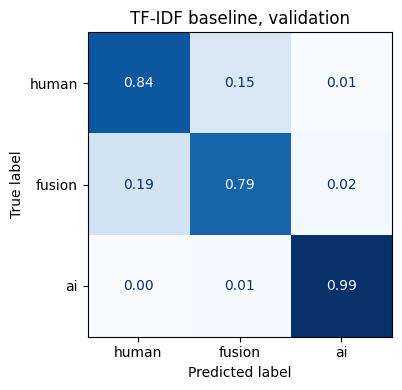

In [8]:
# Figure: confusion matrix on validation, each row normalized to 1 (share of true class predicted as each class)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(val["label"], pred_val, labels=LABELS, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title("TF-IDF baseline, validation")
plt.tight_layout()
plt.savefig(FIG / "baseline_confusion.png", dpi=120)
plt.show()

**Findings.** Errors are almost only between human and fusion: 15% of human texts are called fusion and 19% of fusion
texts are called human. ai is recognized 99% of the time and is rarely confused with fusion (2%).

In [9]:
# Macro-F1 and accuracy per domain on validation (macro-F1 over the classes present in that domain)
res = val.assign(pred=pred_val)
pd.DataFrame({dl: {"texts": len(g), "accuracy": (g["label"] == g["pred"]).mean(),
                   "macro_f1": f1_score(g["label"], g["pred"], labels=sorted(g["label"].unique()),
                                        average="macro", zero_division=0)}
              for dl, g in res.groupby("domain_lang")}).T.round(3).sort_values("macro_f1")

,texts,accuracy,macro_f1
gutenberg | de-DE,43.0,0.907,0.676
arxiv_papers | en-EN,1429.0,0.955,0.716
gutenberg | en-EN,692.0,0.962,0.747
blog_authorship_corpus | en-EN,4053.0,0.782,0.765
house_of_commons | en-EN,3186.0,0.899,0.871
euro_court_cases | en-EN,2759.0,0.897,0.882
bundestag | de-DE,5234.0,0.900,0.893
student_essays | en-EN,5411.0,0.909,0.897
cnn_news | en-EN,4429.0,0.921,0.905


**Findings.** The lowest macro-F1 is in gutenberg and arxiv, although accuracy there is high (91–96%): these domains are
mostly ai, and the few human and fusion texts are often mistaken for each other (gutenberg de has only 43 validation
texts, so its score is noisy). Among large domains, blogs are the weakest (accuracy 0.78). Test has more gutenberg,
arxiv and blogs than train, so these are the domains to improve.

In [10]:
# Class scores for validation and test (kept for ensembles) and the Kaggle submission
def class_scores(model, X):
    s = model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)
    return pd.DataFrame(s, columns=[f"s_{c}" for c in model.classes_])

X_test = featurize(test)
pd.concat([val[["id", "label"]], class_scores(final_model, X_val)], axis=1).to_csv(run.pred_path("val"), index=False)
pd.concat([test[["id"]], class_scores(final_model, X_test)], axis=1).to_csv(run.pred_path("test"), index=False)
sub = make_submission(test["id"], final_model.predict(X_test), P.repo / "submissions" / "baseline_tfidf.csv", P.data)

submission saved: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/submissions/baseline_tfidf.csv  (25000 rows)
label
ai        0.517
human     0.261
fusion    0.222


In [11]:
# Distinct warnings logged in this session (should be empty), total time
print(f"total: {(time.time() - NOTEBOOK_START) / 60:.1f} min")
env.warnings_summary(P)

total: 56.1 min


[]